# TP 2 : Histogramme et Seuillage d'Image

Pour utiliser votre image : mettez son chemin dans `IMAGE_PATH`. Sinon, une image synthétique (sombre, peu contrastée) est créée.

In [9]:
import numpy as np, cv2, pandas as pd
import matplotlib.pyplot as plt

IMAGE_PATH = "./image.png"   # ex: "image.jpg"

def make(lo, hi, uneven=False):
    """Image synthétique : 2 objets clairs sur fond sombre, gris entre lo et hi."""
    base = np.zeros((300, 400), np.uint8)
    cv2.circle(base, (110, 150), 60, 255, -1)
    cv2.rectangle(base, (230, 70), (350, 190), 255, -1)
    f = base / 255 * 0.5 + 0.25
    if uneven:
        f = f * np.linspace(0.3, 1, 400)[None, :]      # éclairage inégal
    f = (f - f.min()) / (f.max() - f.min())
    f = lo + f * (hi - lo) + np.random.default_rng(0).normal(0, 3, f.shape)
    return np.clip(f, 0, 255).astype(np.uint8)

def make_doc():
    """Document scanné mal éclairé : texte sombre, fond clair, gradient."""
    txt = np.zeros((300, 400), np.uint8)
    for i, t in enumerate(["Histogramme", "Seuillage", "Otsu", "Adaptatif"]):
        cv2.putText(txt, t, (20, 60 + i * 65), cv2.FONT_HERSHEY_SIMPLEX, 1.4, 255, 3)
    f = np.linspace(0.3, 1, 400)[None, :] * (230 - 170 * txt / 255)
    f = f + np.random.default_rng(1).normal(0, 4, f.shape)
    return np.clip(f, 0, 255).astype(np.uint8)

if IMAGE_PATH:
    img = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
else:
    img = make(100, 145)          # image peu contrastée
doc = make_doc()

def show(images, titles, hist=True):
    """Images + leurs histogrammes."""
    n = len(images)
    fig, ax = plt.subplots(2 if hist else 1, n, figsize=(4 * n, 6 if hist else 3), squeeze=False)
    for j, (im, t) in enumerate(zip(images, titles)):
        ax[0, j].imshow(im, cmap="gray", vmin=0, vmax=255)
        ax[0, j].set_title(t); ax[0, j].axis("off")
        if hist:
            ax[1, j].hist(im.ravel(), bins=256, range=(0, 256)); ax[1, j].set_xlim(0, 255)
    plt.tight_layout(); plt.show()

# Exercice 1 : Histogramme

## 1. Affichage et analyse

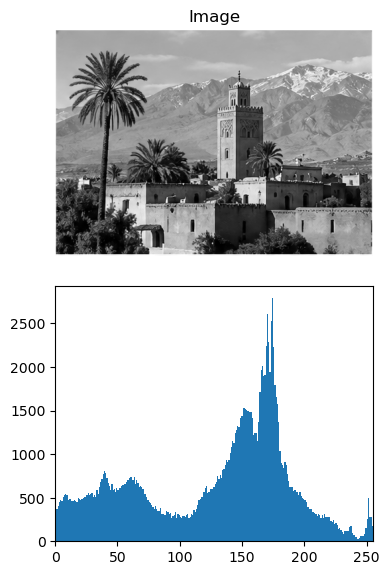

min = 0 | max = 255 | moyenne = 127 | écart-type = 62


In [10]:
show([img], ["Image"])
print("min =", img.min(), "| max =", img.max(), "| moyenne =", round(img.mean()), "| écart-type =", round(img.std()))

**Analyse :** l'histogramme est étroit (écart-type faible) : les niveaux de gris occupent une petite partie de [0, 255]. L'image a donc un **faible contraste**. Un pic à gauche = image sombre, à droite = image claire.

## 2. Étirement linéaire

$g = 255 \times \dfrac{f - f_{min}}{f_{max} - f_{min}}$ : on étale la plage utilisée sur [0, 255].

## 3. Égalisation d'histogramme

On utilise la fonction de répartition cumulée pour aplatir l'histogramme.

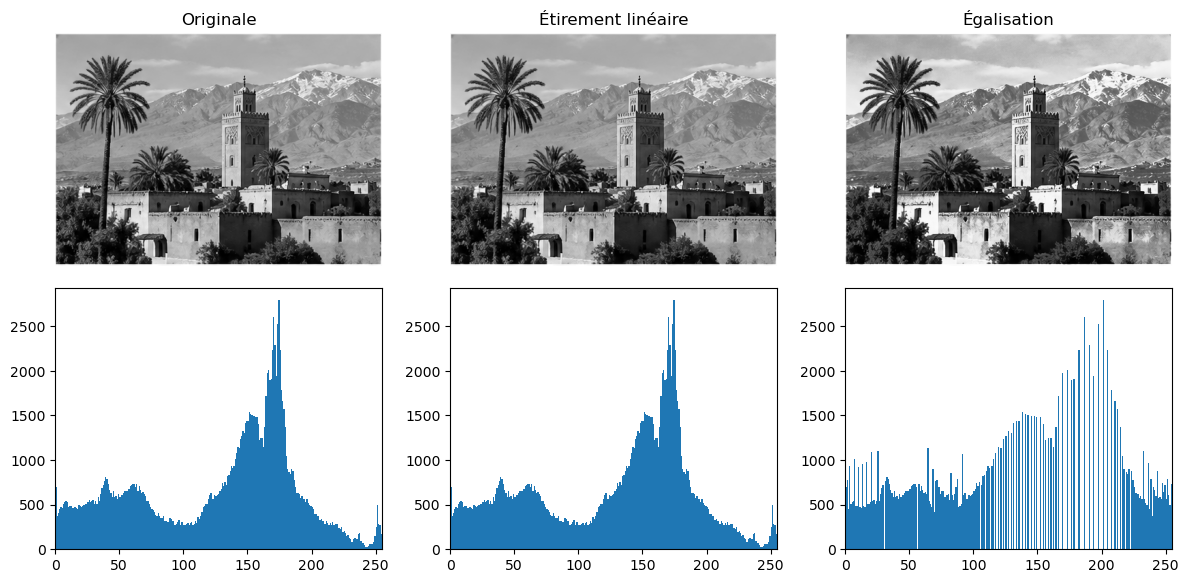

In [11]:
stretch = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX)   # étirement linéaire
equal = cv2.equalizeHist(img)                                  # égalisation

show([img, stretch, equal], ["Originale", "Étirement linéaire", "Égalisation"])

**Comparaison :**
- **Étirement** : transformation linéaire, la forme de l'histogramme est conservée. Résultat naturel.
- **Égalisation** : transformation non linéaire, l'histogramme devient plat. Contraste plus fort, mais le bruit est aussi amplifié.

# Exercice 2 : Seuillage

## 1. Seuillage global fixe

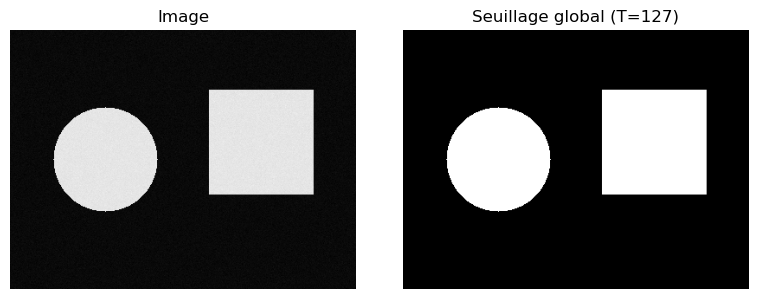

In [12]:
img2 = make(10, 230)                      # image bien contrastée
_, glob = cv2.threshold(img2, 127, 255, cv2.THRESH_BINARY)
show([img2, glob], ["Image", "Seuillage global (T=127)"], hist=False)

## 2. Seuillage d'Otsu

Otsu cherche automatiquement le seuil `T` qui sépare le mieux les deux groupes de pixels (objet / fond). Il suppose un histogramme à **deux pics**.

Seuil d'Otsu = 24.0


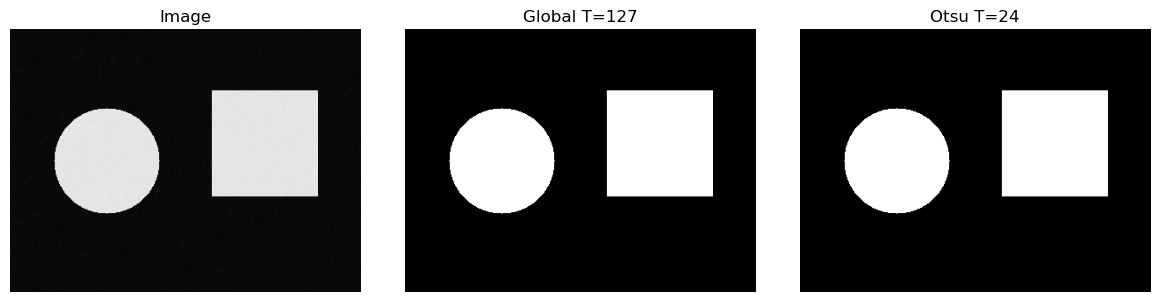

In [13]:
T, otsu = cv2.threshold(img2, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Seuil d'Otsu =", T)
show([img2, glob, otsu], ["Image", "Global T=127", f"Otsu T={T:.0f}"], hist=False)

## 3. Seuillage adaptatif (moyenne et gaussien)

Le seuil est calculé **pour chaque pixel** avec son voisinage. Utile quand l'éclairage n'est pas uniforme : exemple avec un document mal éclairé.

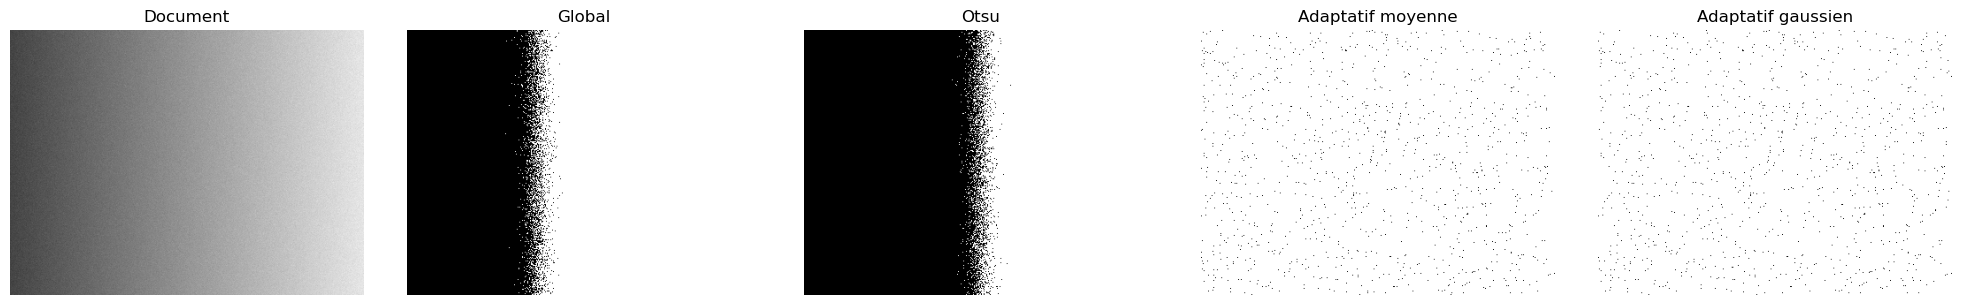

In [14]:
_, doc_glob = cv2.threshold(doc, 127, 255, cv2.THRESH_BINARY)
_, doc_otsu = cv2.threshold(doc, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
doc_mean = cv2.adaptiveThreshold(doc, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 31, 10)
doc_gauss = cv2.adaptiveThreshold(doc, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 31, 10)

show([doc, doc_glob, doc_otsu, doc_mean, doc_gauss],
     ["Document", "Global", "Otsu", "Adaptatif moyenne", "Adaptatif gaussien"], hist=False)

**Observations :**
- Global et Otsu utilisent **un seul seuil** : une partie du document (le côté sombre) est perdue.
- L'adaptatif s'adapte à l'éclairage local : le texte est lisible partout.
- Gaussien : un peu plus propre que la moyenne (il donne plus de poids aux pixels proches).

# Exercice 3 : Tableau

| Type d'image | Histogramme | Méthode la plus adaptée | Pourquoi ? |
|---|---|---|---|
| Image sombre et homogène | Étroit, collé à gauche | Étirement linéaire (ou égalisation) | Éclairage uniforme : une transformation globale suffit pour étaler la plage |
| Image bruitée | Pics étalés, vallée peu nette | Filtre (médian / gaussien) puis Otsu | L'égalisation amplifierait le bruit ; lisser d'abord rend l'histogramme bimodal |
| Document scanné mal éclairé | Pas de vallée nette, éclairage variable | Seuillage adaptatif (gaussien) | Le seuil s'ajuste localement à l'éclairage |
| Image médicale | Étroit, détails fins | CLAHE | Rehausse le contraste local sans trop amplifier le bruit |

# Exercice 4 : CLAHE + seuillage

CLAHE = égalisation **locale** (par petites tuiles) avec une limite d'amplification (`clipLimit`).

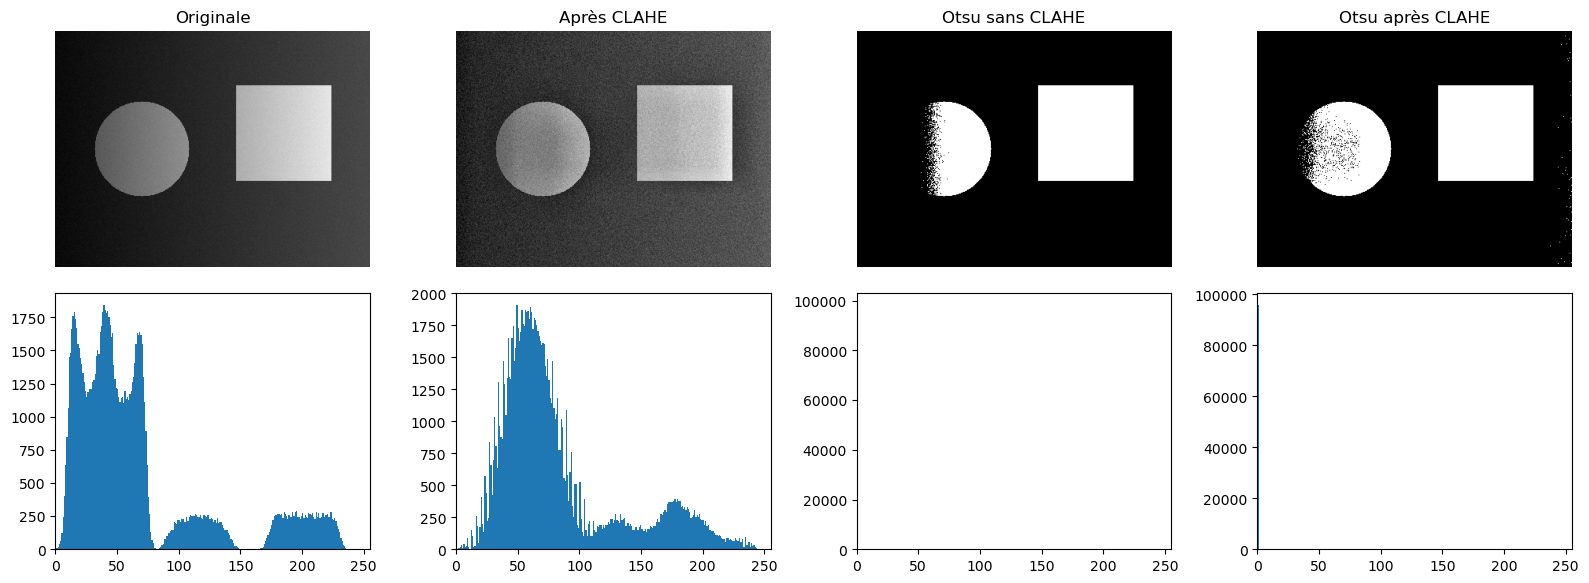

In [15]:
low = make(10, 230, uneven=True)           # image peu contrastée, éclairage inégal

clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(low)

_, otsu_avant = cv2.threshold(low, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_, otsu_apres = cv2.threshold(clahe, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

show([low, clahe, otsu_avant, otsu_apres],
     ["Originale", "Après CLAHE", "Otsu sans CLAHE", "Otsu après CLAHE"])

**Amélioration :** sans CLAHE, la zone sombre est mal segmentée ; après CLAHE, le contraste local est rétabli et Otsu retrouve les deux objets.

---
# Problème : contrôle qualité industriel

## Partie 1 : Analyse et conception

**1. Que révèle l'histogramme ?** Il est **écrasé** (étroit) sur la gauche (image sombre) ou sur la droite (image trop claire), avec un faible écart-type : le contraste est faible et l'objet se confond avec le fond.

**2. Technique d'amélioration : CLAHE.**
- *Étirement* : trop simple, ne corrige pas un éclairage inégal.
- *Égalisation globale* : une seule correction pour toute l'image et amplifie le bruit.
- *CLAHE* : corrige localement, avec amplification limitée. Adapté à un éclairage industriel qui varie.

**3. Méthode de seuillage : Otsu** (après CLAHE).
- *Global fixe* : écarté, le bon seuil change avec l'éclairage.
- *Otsu* : seuil calculé automatiquement pour chaque image.
- *Adaptatif* : à utiliser seulement s'il reste un gradient d'éclairage.

**Schéma du pipeline :**

```
Image  →  Filtre médian  →  CLAHE  →  Seuillage Otsu  →  Nettoyage (morphologie)  →  Objet extrait
          (réduit bruit)   (contraste)   (sépare objet/fond)   (enlève les petits points)
```

## Partie 2 : Implémentation Python

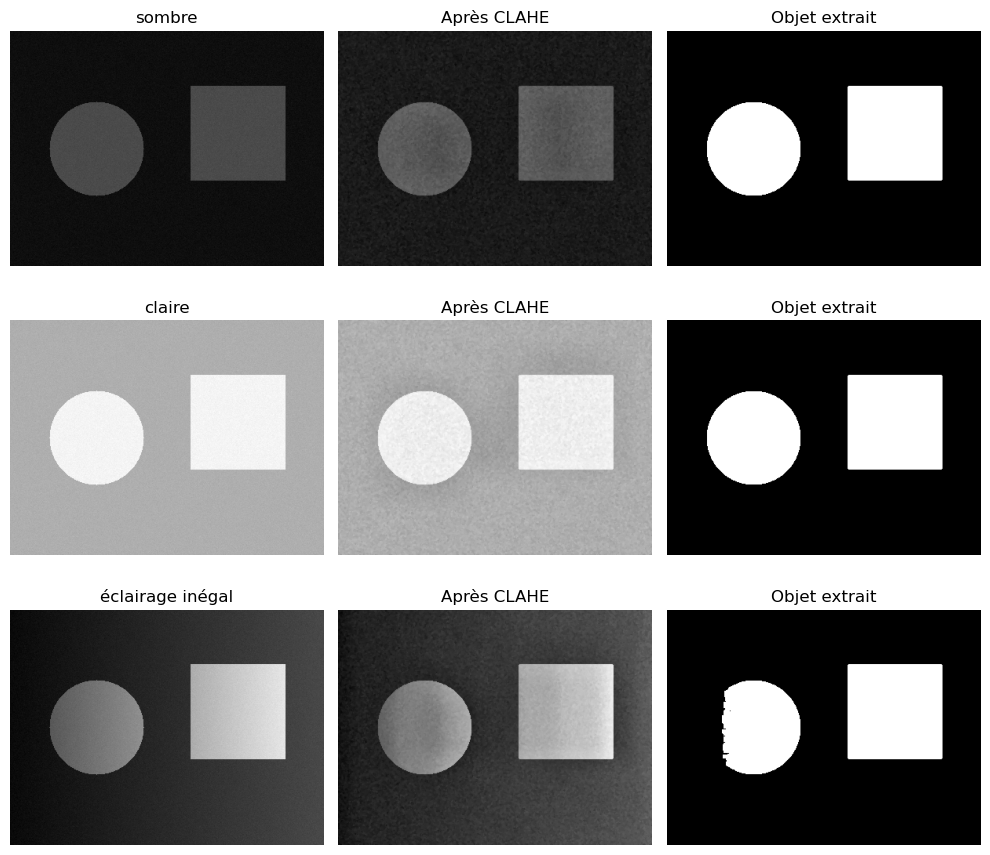

In [16]:
def pipeline(gray):
    e = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(cv2.medianBlur(gray, 3))   # filtre + CLAHE
    _, m = cv2.threshold(e, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)                      # Otsu
    if m.mean() > 127:                                    # l'objet doit être en blanc et minoritaire
        m = 255 - m
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))                        # nettoyage
    return e, m

cas = {"sombre": make(15, 75), "claire": make(175, 245), "éclairage inégal": make(10, 230, uneven=True)}

fig, ax = plt.subplots(3, 3, figsize=(10, 9))
for r, (nom, im) in enumerate(cas.items()):
    e, m = pipeline(im)
    for c, (x, t) in enumerate([(im, nom), (e, "Après CLAHE"), (m, "Objet extrait")]):
        ax[r, c].imshow(x, cmap="gray", vmin=0, vmax=255); ax[r, c].set_title(t); ax[r, c].axis("off")
plt.tight_layout(); plt.show()

**Conclusion :** l'histogramme sert à **diagnostiquer** l'image ; CLAHE corrige le contraste localement ; Otsu sépare l'objet du fond automatiquement ; l'adaptatif sert quand l'éclairage reste inégal.